<a href="https://colab.research.google.com/github/sivakumarmahalakshmi27-commits/Urban-Pulse---Guvi-mini-project-1/blob/main/Project_Data_cleaning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data cleaning

In [ ]:
!pip -q install requests pandas

In [ ]:
import requests
import pandas as pd

In [ ]:
import os
print(os.getcwd())
print(os.listdir())

/content
['.config', 'sample_data']


In [ ]:
os.rename("nyc311_raw Final.csv", "nyc311_raw.csv")

## Cell 1: Load

In [ ]:
import pandas as pd, numpy as np

path = "nyc311_raw.csv"
raw = pd.read_csv(path, dtype={"unique_key": str, "incident_zip": str}, low_memory=False)
print(raw.shape)
raw.head()

(118866, 23)


,unique_key,created_date,closed_date,agency,agency_name,complaint_type,descriptor,location_type,incident_zip,incident_address,...,status,resolution_description,resolution_action_updated_date,community_board,open_data_channel_type,park_borough,latitude,longitude,facility_type,due_date
0,66675637,2025-10-31T23:59:32.000,2025-11-01T01:12:16.000,NYPD,New York City Police Department,Noise - Residential,Loud Talking,Residential Building/House,10025,249 WEST 109 STREET,...,Closed,The Police Department responded to the complai...,2025-11-01T01:12:19.000,07 MANHATTAN,PHONE,MANHATTAN,40.803040,-73.965859,NaN,NaN
1,66682507,2025-10-31T23:58:54.000,2025-11-01T05:14:33.000,NYPD,New York City Police Department,Blocked Driveway,No Access,Street/Sidewalk,11385,74-25 CYPRESS HILLS STREET,...,Closed,The Police Department responded to the complai...,2025-11-01T05:14:37.000,05 QUEENS,MOBILE,QUEENS,40.699929,-73.889192,NaN,NaN
2,66685107,2025-10-31T23:55:03.000,2025-11-01T01:34:28.000,NYPD,New York City Police Department,Noise - Commercial,Loud Music/Party,Club/Bar/Restaurant,11222,151 BANKER STREET,...,Closed,The Police Department responded to the complai...,2025-11-01T01:34:30.000,01 BROOKLYN,ONLINE,BROOKLYN,40.723974,-73.954925,NaN,NaN
3,66680337,2025-10-31T23:53:28.000,2025-10-31T23:57:30.000,NYPD,New York City Police Department,Noise - Residential,Loud Music/Party,Residential Building/House,10456,1465 WASHINGTON AVENUE,...,Closed,The Police Department responded to the complai...,2025-10-31T23:57:33.000,03 BRONX,ONLINE,BRONX,40.836941,-73.903744,NaN,NaN
4,66675807,2025-10-31T23:51:41.000,2025-11-02T14:08:09.000,HPD,Department of Housing Preservation and Develop...,HEAT/HOT WATER,ENTIRE BUILDING,RESIDENTIAL BUILDING,11373,42-01 LAYTON STREET,...,Closed,This complaint is a duplicate of a building-wi...,2025-11-02T14:08:09.000,04 QUEENS,ONLINE,QUEENS,40.744519,-73.884484,NaN,NaN


## Cell 2: Inspect

In [ ]:
print(raw.dtypes)
print("\nMissing % per column:\n", (raw.isna().mean() * 100).round(1).sort_values(ascending=False))
print("\nDuplicate keys:", raw["unique_key"].duplicated().sum())
print("\nDate range:", raw["created_date"].min(), "to", raw["created_date"].max())
print("\n", raw["borough"].value_counts(dropna=False))
print("\n", raw["status"].value_counts(dropna=False))

unique_key                         object
created_date                       object
closed_date                        object
agency                             object
agency_name                        object
complaint_type                     object
descriptor                         object
location_type                      object
incident_zip                       object
incident_address                   object
street_name                        object
city                               object
borough                            object
status                             object
resolution_description             object
resolution_action_updated_date     object
community_board                    object
open_data_channel_type             object
park_borough                       object
latitude                          float64
longitude                         float64
facility_type                      object
due_date                           object
dtype: object

Missing % per colum

## Cell 3: Data Dictionary Draft

In [ ]:
dd = pd.DataFrame({
    "source_column": raw.columns,
    "raw_dtype": raw.dtypes.astype(str).values,
    "missing_count": raw.isna().sum().values,
    "missing_pct": (raw.isna().mean() * 100).round(2).values,
    "unique_values": raw.nunique().values,
    "example_value": [raw[c].dropna().iloc[0] if raw[c].notna().any() else None for c in raw.columns],
})
dd["meaning"] = ""
dd["transformation"] = ""
dd["analytical_use"] = ""
dd.to_csv("data_dictionary_draft.csv", index=False)
dd

,source_column,raw_dtype,missing_count,missing_pct,unique_values,example_value,meaning,transformation,analytical_use
0,unique_key,object,0,0.00,118866,66675637,,,
1,created_date,object,0,0.00,117616,2025-10-31T23:59:32.000,,,
2,closed_date,object,4179,3.52,106333,2025-11-01T01:12:16.000,,,
3,agency,object,0,0.00,16,NYPD,,,
4,agency_name,object,0,0.00,16,New York City Police Department,,,
5,complaint_type,object,0,0.00,172,Noise - Residential,,,
6,descriptor,object,2280,1.92,793,Loud Talking,,,
7,location_type,object,14568,12.26,116,Residential Building/House,,,
8,incident_zip,object,1061,0.89,225,10025,,,
9,incident_address,object,4460,3.75,70983,249 WEST 109 STREET,,,


## Cell 4: Duplicates


In [ ]:
df = raw.copy()
log = [("Raw rows loaded", len(raw))]

dups = int(df["unique_key"].duplicated().sum())
df = df.drop_duplicates(subset="unique_key", keep="first")
log.append(("Duplicate unique_key rows removed", dups))

## Cell 5: Date (Data type problems)

In [ ]:
date_cols = ["created_date", "closed_date", "due_date", "resolution_action_updated_date"]
for c in date_cols:
    before = df[c].notna().sum()
    df[c] = pd.to_datetime(df[c], errors="coerce")
    log.append((f"{c}: values that failed to parse", int(before - df[c].notna().sum())))

## Cell 6: Text and categories

In [ ]:
text_cols = [c for c in df.columns if c not in date_cols + ["latitude", "longitude"]]
for c in text_cols:
    df[c] = (df[c].astype("string").str.strip()
               .str.replace(r"\s+", " ", regex=True).replace("", pd.NA))

for c in ["borough", "agency", "city", "park_borough", "open_data_channel_type"]:
    df[c] = df[c].str.upper()
log.append((f"Text columns trimmed; 5 columns uppercased", len(text_cols)))

# Merge case variants of complaint_type (e.g. 'Plumbing' / 'PLUMBING') into the most common form
key = df["complaint_type"].str.upper()
canon = df.groupby(key)["complaint_type"].agg(lambda s: s.value_counts().index[0])
changed = int((df["complaint_type"] != key.map(canon)).sum())
df["complaint_type"] = key.map(canon)
log.append(("complaint_type rows with case variants standardised", changed))

# ZIP format check
df["zip_invalid_flag"] = df["incident_zip"].notna() & ~df["incident_zip"].str.fullmatch(r"\d{5}", na=False)
log.append(("Invalid ZIP format (flagged)", int(df["zip_invalid_flag"].sum())))

## Cell 7: Coordinates

In [ ]:
df["latitude"] = pd.to_numeric(df["latitude"], errors="coerce")
df["longitude"] = pd.to_numeric(df["longitude"], errors="coerce")

df["coord_missing_flag"] = df["latitude"].isna() | df["longitude"].isna()
df["coord_out_of_nyc_flag"] = (~df["coord_missing_flag"]) & ~(
    df["latitude"].between(40.4, 41.0) & df["longitude"].between(-74.3, -73.6))

log.append(("Missing coordinates", int(df["coord_missing_flag"].sum())))
log.append(("Coordinates outside NYC box", int(df["coord_out_of_nyc_flag"].sum())))

## Cell 8: Derived fields and quality flags

In [ ]:
now = pd.Timestamp.now()

df["is_closed"] = df["closed_date"].notna().astype(int)
df["closed_before_created_flag"] = df["closed_date"] < df["created_date"]
df["future_date_flag"] = (df["created_date"] > now) | (df["closed_date"] > now)
df["status_closed_mismatch_flag"] = (df["is_closed"] == 1) & (df["status"] != "Closed")

df["resolution_hours"] = (df["closed_date"] - df["created_date"]).dt.total_seconds() / 3600
bad = df["closed_before_created_flag"] | df["future_date_flag"]
df.loc[bad, "resolution_hours"] = np.nan      # flagged rows kept; duration left blank

df["created_date_only"] = df["created_date"].dt.date
df["created_year"] = df["created_date"].dt.year
df["created_month"] = df["created_date"].dt.month
df["created_ym"] = df["created_date"].dt.to_period("M").astype(str)
df["created_weekday"] = df["created_date"].dt.day_name()
df["created_hour"] = df["created_date"].dt.hour

log.append(("Closed before created (flagged)", int(df["closed_before_created_flag"].sum())))
log.append(("Future dates (flagged)", int(df["future_date_flag"].sum())))
log.append(("Closed date present but status not Closed (flagged)", int(df["status_closed_mismatch_flag"].sum())))
log.append(("Rows with valid resolution_hours", int(df["resolution_hours"].notna().sum())))
log.append(("Final cleaned rows", len(df)))
df["action_before_created_flag"] = df["resolution_action_updated_date"] < df["created_date"]
log.append(("Action-updated before created (flagged)", int(df["action_before_created_flag"].sum())))

## Cell 9: Review, save and download

In [ ]:
log_df = pd.DataFrame(log, columns=["step", "count"])
display(log_df)
print(df["resolution_hours"].describe())
print("Skewness:", df["resolution_hours"].skew())
print("Share over 72h:", (df["resolution_hours"] > 72).sum() / df["resolution_hours"].notna().sum())
print(df["created_ym"].value_counts().sort_index())

df.to_csv("nyc311_clean.csv", index=False)
log_df.to_csv("cleaning_log.csv", index=False)

from google.colab import files
for f in ["nyc311_clean.csv", "cleaning_log.csv", "data_dictionary_draft.csv"]:
    files.download(f)

,step,count
0,Raw rows loaded,118866
1,Duplicate unique_key rows removed,0
2,created_date: values that failed to parse,0
3,closed_date: values that failed to parse,0
4,due_date: values that failed to parse,0
5,resolution_action_updated_date: values that fa...,0
6,Text columns trimmed; 5 columns uppercased,17
7,complaint_type rows with case variants standar...,192
8,Invalid ZIP format (flagged),0
9,Missing coordinates,2429


count    114660.000000
mean        166.851655
std         520.015437
min           0.000000
25%           1.166667
50%           7.662222
75%          77.497639
max        9261.190556
Name: resolution_hours, dtype: float64
Skewness: 6.4034100513460475
Share over 72h: 0.2622623408337694
created_ym
2025-10    10062
2025-11     9152
2025-12     9962
2026-01    10444
2026-02    10031
2026-03    10281
2026-04     9085
2026-05     9961
2026-06    10051
2026-07    10282
2026-08     9843
2026-09     9712
Name: count, dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Cell 10: Verification Cell

In [ ]:
print("Rows: raw", len(raw), "| cleaned", len(df))
print("Duplicate unique_key after cleaning:", df["unique_key"].duplicated().sum())
print("Duplicate full rows after cleaning:", df.duplicated().sum())

nulls = pd.DataFrame({"null_count": df.isna().sum(),
                      "null_pct": (df.isna().mean() * 100).round(2)})
print(nulls[nulls.null_count > 0].sort_values("null_count", ascending=False))

print("\nDate ranges:")
for c in ["created_date", "closed_date", "resolution_action_updated_date", "due_date"]:
    print(f"  {c}: {df[c].min()} -> {df[c].max()}")
print("Latitude range:", df["latitude"].min(), df["latitude"].max())
print("Longitude range:", df["longitude"].min(), df["longitude"].max())
print("resolution_hours min/max:", df["resolution_hours"].min(), df["resolution_hours"].max())
print("Negative resolution_hours remaining:", (df["resolution_hours"] < 0).sum())

print("\nUnique values:")
for c in ["borough", "status", "open_data_channel_type"]:
    print(f"  {c}: {sorted(df[c].dropna().unique())}")
print("\nEmpty-string cells remaining:",
      (df.select_dtypes(include=["object", "string"]) == "").sum().sum())
print("\nFinal dtypes:\n", df.dtypes)

Rows: raw 118866 | cleaned 118866
Duplicate unique_key after cleaning: 0
Duplicate full rows after cleaning: 0
                                null_count  null_pct
facility_type                       118537     99.72
due_date                            118441     99.64
location_type                        14568     12.26
city                                  6054      5.09
street_name                           4461      3.75
incident_address                      4460      3.75
resolution_hours                      4206      3.54
closed_date                           4179      3.52
resolution_description                2708      2.28
latitude                              2429      2.04
longitude                             2429      2.04
descriptor                            2280      1.92
resolution_action_updated_date        1632      1.37
incident_zip                          1061      0.89

Date ranges:
  created_date: 2025-10-01 00:06:27 -> 2026-09-30 23:57:00
  closed_date: 2025-1

### Sample data extraction after data cleaning.

In [ ]:
from google.colab import files
df.sample(20000, random_state=1).to_csv("nyc311_clean_sample20k.csv", index=False)
files.download("nyc311_clean_sample20k.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Cross Verification

In [ ]:
valid = df["resolution_hours"].dropna()
strict = df.loc[~df["status_closed_mismatch_flag"], "resolution_hours"].dropna()

print("Median:  all", round(valid.median(), 2), "| excluding mismatches", round(strict.median(), 2))
print("Mean:    all", round(valid.mean(), 2), "| excluding mismatches", round(strict.mean(), 2))
print("Over 72h: all", round((valid > 72).mean() * 100, 2), "% | excluding", round((strict > 72).mean() * 100, 2), "%")

Median:  all 7.66 | excluding mismatches 7.68
Mean:    all 166.85 | excluding mismatches 166.04
Over 72h: all 26.23 % | excluding 26.18 %


## Cell 11: Descriptive statistics

In [ ]:
rh = df["resolution_hours"].dropna()

stats = {
    "count": rh.count(), "mean": rh.mean(), "median": rh.median(),
    "mode (rounded to 1h)": rh.round(0).mode().iloc[0],
    "min": rh.min(), "max": rh.max(), "range": rh.max() - rh.min(),
    "Q1": rh.quantile(0.25), "Q3": rh.quantile(0.75),
    "variance": rh.var(), "std": rh.std(),
    "skewness": rh.skew(), "kurtosis": rh.kurt(),
    "p90": rh.quantile(0.90), "p95": rh.quantile(0.95), "p99": rh.quantile(0.99),
}
stats["IQR"] = stats["Q3"] - stats["Q1"]
stats_df = pd.DataFrame(stats, index=["resolution_hours"]).T.round(2)
stats_df

NameError: name 'df' is not defined

## Cell 12: IQR outlier screening

In [ ]:
Q1, Q3, IQR = stats["Q1"], stats["Q3"], stats["IQR"]
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
print(f"Lower fence: {lower:.2f} h | Upper fence: {upper:.2f} h")

df["resolution_outlier_flag"] = (df["resolution_hours"] < lower) | (df["resolution_hours"] > upper)
n_out = int(df["resolution_outlier_flag"].sum())
print(f"Outliers flagged: {n_out} ({n_out / len(rh) * 100:.1f}% of valid durations)")
print("Share of durations over 72 h:", round((rh > 72).mean() * 100, 1), "%")

print("\nOutliers by agency:\n", df[df.resolution_outlier_flag].groupby("agency").size().sort_values(ascending=False).head(5))
print("\nOutliers by complaint type:\n", df[df.resolution_outlier_flag].groupby("complaint_type").size().sort_values(ascending=False).head(5))

Lower fence: -113.33 h | Upper fence: 191.99 h
Outliers flagged: 17869 (15.6% of valid durations)
Share of durations over 72 h: 26.2 %

Outliers by agency:
 agency
HPD      9426
DOT      2148
DOB      1691
DOHMH    1208
DPR      1132
dtype: int64

Outliers by complaint type:
 complaint_type
UNSANITARY CONDITION    2509
PLUMBING                1382
PAINT/PLASTER           1022
DOOR/WINDOW              995
WATER LEAK               873
dtype: int64


### Monthly counts

In [ ]:
df["created_ym"].value_counts().sort_index()

,count
created_ym,
2025-10,10062
2025-11,9152
2025-12,9962
2026-01,10444
2026-02,10031
2026-03,10281
2026-04,9085
2026-05,9961
2026-06,10051


## Cell 13: Histogram and boxplot

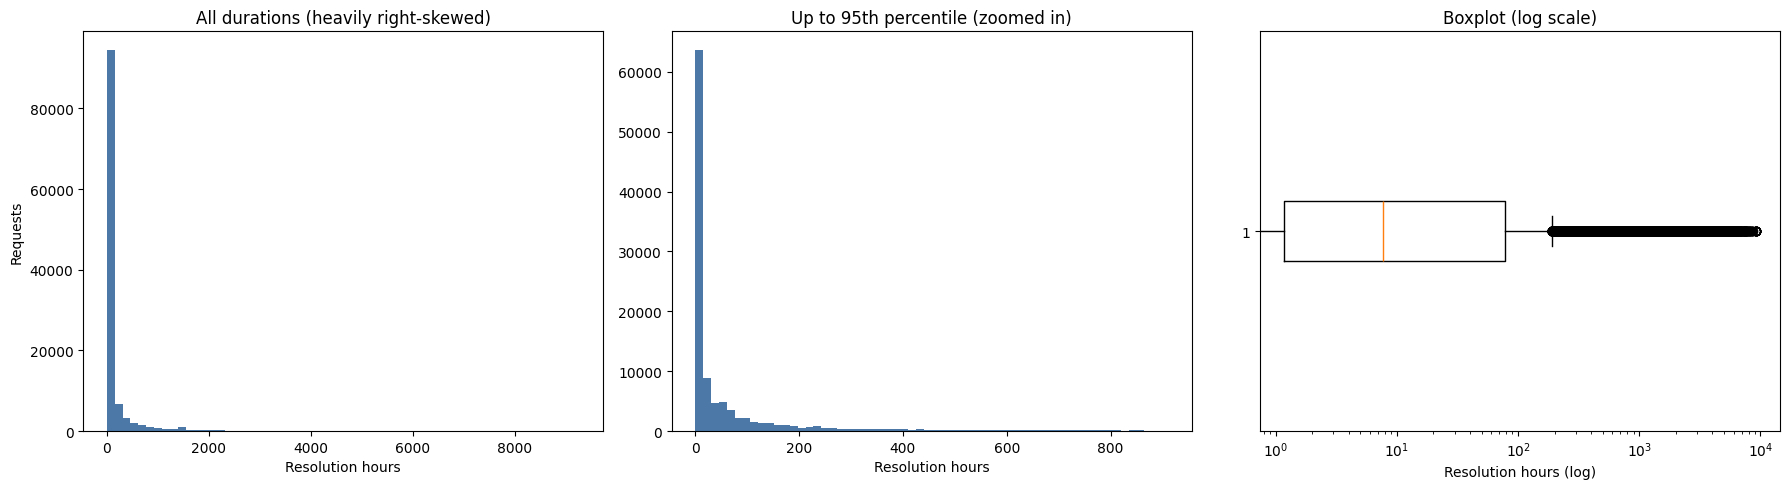

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(rh, bins=60, color="#4C78A8")
axes[0].set_title("All durations (heavily right-skewed)")
axes[0].set_xlabel("Resolution hours"); axes[0].set_ylabel("Requests")

axes[1].hist(rh[rh <= rh.quantile(0.95)], bins=60, color="#4C78A8")
axes[1].set_title("Up to 95th percentile (zoomed in)")
axes[1].set_xlabel("Resolution hours")

axes[2].boxplot(rh, vert=False)
axes[2].set_xscale("log")
axes[2].set_title("Boxplot (log scale)")
axes[2].set_xlabel("Resolution hours (log)")

plt.tight_layout()
fig.savefig("resolution_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

##Cell 14: Save and download

In [ ]:
stats_df.to_csv("resolution_stats.csv")
df.to_csv("nyc311_clean.csv", index=False)     # now includes resolution_outlier_flag

from google.colab import files
for f in ["resolution_stats.csv", "nyc311_clean.csv", "resolution_distribution.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Clearer Data

In [ ]:
import matplotlib.pyplot as plt
rh = df["resolution_hours"].dropna()

NameError: name 'df' is not defined

In [ ]:
import numpy as np
rh_pos = rh[rh > 0]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(rh_pos, bins=np.logspace(np.log10(rh_pos.min()), np.log10(rh_pos.max()), 50), color="#4C78A8")
ax.set_xscale("log")
ax.axvline(rh.median(), color="red", linestyle="--", label=f"Median {rh.median():.1f} h")
ax.axvline(rh.mean(), color="orange", linestyle="--", label=f"Mean {rh.mean():.1f} h")
ax.set_xlabel("Resolution hours (log scale)"); ax.set_ylabel("Requests"); ax.legend()
ax.set_title("Resolution time distribution (log-spaced bins)")
plt.show()

NameError: name 'rh' is not defined